# Project Overview

In [4]:
# Smart Energy Consumption Prediction Using Machine Learning
### Short-Term Electricity Demand Forecasting Using Delhi 5-Minute Energy Data
## Project Objective

##The objective of this project is to develop a machine learning model for short-term electricity demand prediction using Delhi electricity demand data recorded at 5-minute intervals.

## The project focuses on understanding the dataset, performing appropriate data preprocessing and feature engineering, and training machine learning models to predict electricity demand for the next 5-minute interval.

## Import Libraries

In [5]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_regression

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

### Load the Dataset

In [6]:
df = pd.read_csv('ML_Dataset.csv')
df.head()


,Unnamed: 0,datetime,Power demand,temp,dwpt,rhum,wdir,wspd,pres,year,month,day,hour,minute,moving_avg_3
0,0,2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,NaN
1,1,2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,NaN
2,2,2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,1999.076667
3,3,2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,1986.556667
4,4,2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,1969.470000


In [7]:
# Dataset dimensions, structure and statistical summary
print("Dataset shape:", df.shape)
print("\\nDataset information:")
df.info()

print("\\nStatistical summary:")
display(df.describe())


Dataset shape: (393440, 15)
\nDataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 393440 entries, 0 to 393439
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Unnamed: 0    393440 non-null  int64  
 1   datetime      393440 non-null  object 
 2   Power demand  393440 non-null  float64
 3   temp          393440 non-null  float64
 4   dwpt          393440 non-null  float64
 5   rhum          393440 non-null  float64
 6   wdir          392900 non-null  float64
 7   wspd          393440 non-null  float64
 8   pres          393440 non-null  float64
 9   year          393440 non-null  int64  
 10  month         393440 non-null  int64  
 11  day           393440 non-null  int64  
 12  hour          393440 non-null  int64  
 13  minute        393440 non-null  int64  
 14  moving_avg_3  393438 non-null  float64
dtypes: float64(8), int64(6), object(1)
memory usage: 45.0+ MB
\nStatistical summary:


,Unnamed: 0,Power demand,temp,dwpt,rhum,wdir,wspd,pres,year,month,day,hour,minute,moving_avg_3
count,393440.000000,393440.000000,393440.000000,393440.000000,393440.000000,392900.000000,393440.000000,393440.000000,393440.000000,393440.000000,393440.000000,393440.000000,393440.000000,393438.000000
mean,196719.500000,3960.736469,25.527913,16.338046,63.435767,163.777081,7.854550,1008.932695,2022.487129,6.446991,15.745171,11.184371,27.354959,3960.746273
std,113576.489292,1300.473773,7.981563,7.377440,24.850663,116.888397,5.664314,6.902759,1.110587,3.412654,8.783091,6.797501,17.223877,1299.545642
min,0.000000,1302.080000,4.000000,-8.600000,5.000000,0.000000,0.000000,989.600000,2021.000000,1.000000,1.000000,0.000000,0.000000,1307.680000
25%,98359.750000,3074.900000,20.000000,10.400000,44.000000,50.000000,5.400000,1003.000000,2021.000000,3.000000,8.000000,5.000000,10.000000,3075.861667
50%,196719.500000,3832.320000,27.000000,15.400000,67.000000,160.000000,7.600000,1009.000000,2022.000000,6.000000,16.000000,11.000000,25.000000,3831.728333
75%,295079.250000,4870.465000,31.000000,23.900000,84.000000,270.000000,11.200000,1015.000000,2023.000000,9.000000,23.000000,17.000000,40.000000,4869.906667
max,393439.000000,8631.530000,46.400000,30.300000,100.000000,360.000000,63.000000,1027.000000,2024.000000,12.000000,31.000000,23.000000,55.000000,8598.126667


## Missing Value Analysis
Missing values are examined for every column to determine whether
imputation or removal is required during preprocessing.

In [8]:
missing_count = df.isnull().sum()
missing_percentage = (
    df.isnull().sum() / len(df) * 100
)
missing_summary = pd.DataFrame({
    'Missing Count': missing_count,
    'Missing Percentage': missing_percentage
})

missing_summary

,Missing Count,Missing Percentage
Unnamed: 0,0,0.000000
datetime,0,0.000000
Power demand,0,0.000000
temp,0,0.000000
dwpt,0,0.000000
rhum,0,0.000000
wdir,540,0.137251
wspd,0,0.000000
pres,0,0.000000
year,0,0.000000


##  Identification of Numerical and Categorical Features
The features are divided into numerical and categorical variables based
on their data types. This classification helps determine the appropriate
preprocessing techniques for each feature.

In [9]:
# Identify numerical and categorical features
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include='object').columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)


Numerical columns: ['Unnamed: 0', 'Power demand', 'temp', 'dwpt', 'rhum', 'wdir', 'wspd', 'pres', 'year', 'month', 'day', 'hour', 'minute', 'moving_avg_3']
Categorical columns: ['datetime']


## Duplicate Record Analysis
Duplicate records are checked because repeated observations can
introduce bias into the analysis and machine learning model.

In [10]:
duplicate_count = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


## Removing the Unnecessary Index Column
The `Unnamed: 0` column represents the original dataframe index and does
not provide meaningful information about electricity demand or weather
conditions. Therefore, it is removed before further analysis.

In [11]:
df = df.drop(columns=['Unnamed: 0'])
df.head()

,datetime,Power demand,temp,dwpt,rhum,wdir,wspd,pres,year,month,day,hour,minute,moving_avg_3
0,2021-01-01 00:30:00,2014.00,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,30,NaN
1,2021-01-01 00:35:00,2005.63,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,35,NaN
2,2021-01-01 00:40:00,1977.60,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,40,1999.076667
3,2021-01-01 00:45:00,1976.44,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,45,1986.556667
4,2021-01-01 00:50:00,1954.37,8.0,6.9,93.0,0.0,0.0,1017.0,2021,1,1,0,50,1969.470000


## Datetime Conversion
The `datetime` column is initially stored as a text/object value.
It is converted into datetime format so that temporal information such
as year, month, day, hour, minute and day of the week can be extracted
for analysis and feature engineering.

In [12]:
# Convert timestamps, sort records and inspect interval consistency
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

print("Dataset period:", df['datetime'].min(), "to", df['datetime'].max())
print("Duplicate timestamps:", df['datetime'].duplicated().sum())

time_difference = df['datetime'].diff()
interval_summary = time_difference.value_counts().head(10)
display(interval_summary.rename_axis("Interval").to_frame("Count"))

five_minute_intervals = (time_difference == pd.Timedelta(minutes=5)).sum()
unusual_intervals = (time_difference.notna() & (time_difference != pd.Timedelta(minutes=5))).sum()

print("Five-minute intervals:", five_minute_intervals)
print("Non-five-minute intervals:", unusual_intervals)


Dataset period: 2021-01-01 00:30:00 to 2024-12-12 00:30:00
Duplicate timestamps: 0


,Count
Interval,
0 days 00:05:00,392289
0 days 00:10:00,272
0 days 00:15:00,267
0 days 00:20:00,93
0 days 01:20:00,52
0 days 01:25:00,46
0 days 00:25:00,42
0 days 01:05:00,37
0 days 01:10:00,33


Five-minute intervals: 392289
Non-five-minute intervals: 1150


## Power Demand Distribution
The distribution of electricity demand is visualized to understand its
central tendency, spread and possible skewness or extreme values.

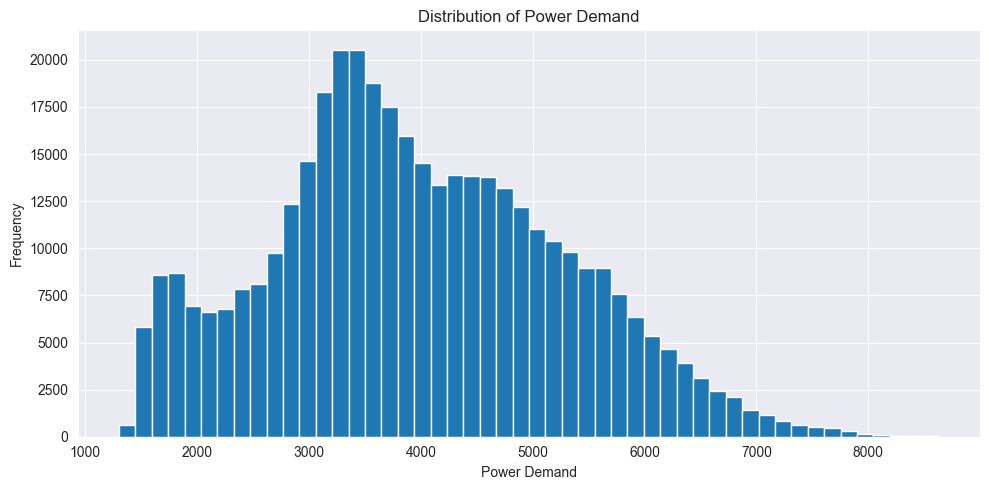

In [13]:
# Plot the distribution of electricity demand
plt.figure(figsize=(10, 5))
plt.hist(df['Power demand'].dropna(), bins=50)
plt.title('Distribution of Power Demand')
plt.xlabel('Power Demand')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


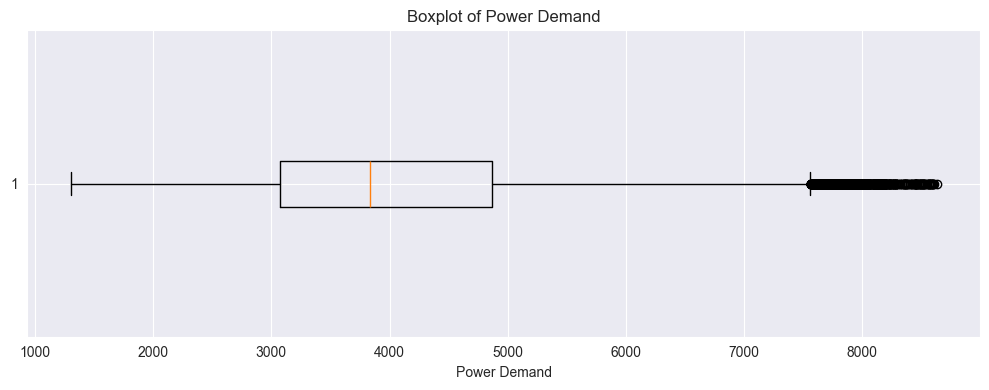

In [14]:
### 11.1 Boxplot of Power Demand
plt.figure(figsize=(10, 4))
plt.boxplot(df['Power demand'].dropna(), vert=False)
plt.title('Boxplot of Power Demand')
plt.xlabel('Power Demand')
plt.tight_layout()
plt.show()


## Power Demand Over Time

The electricity demand is plotted against time to observe long-term
patterns, fluctuations and changes in electricity consumption across
the dataset period.

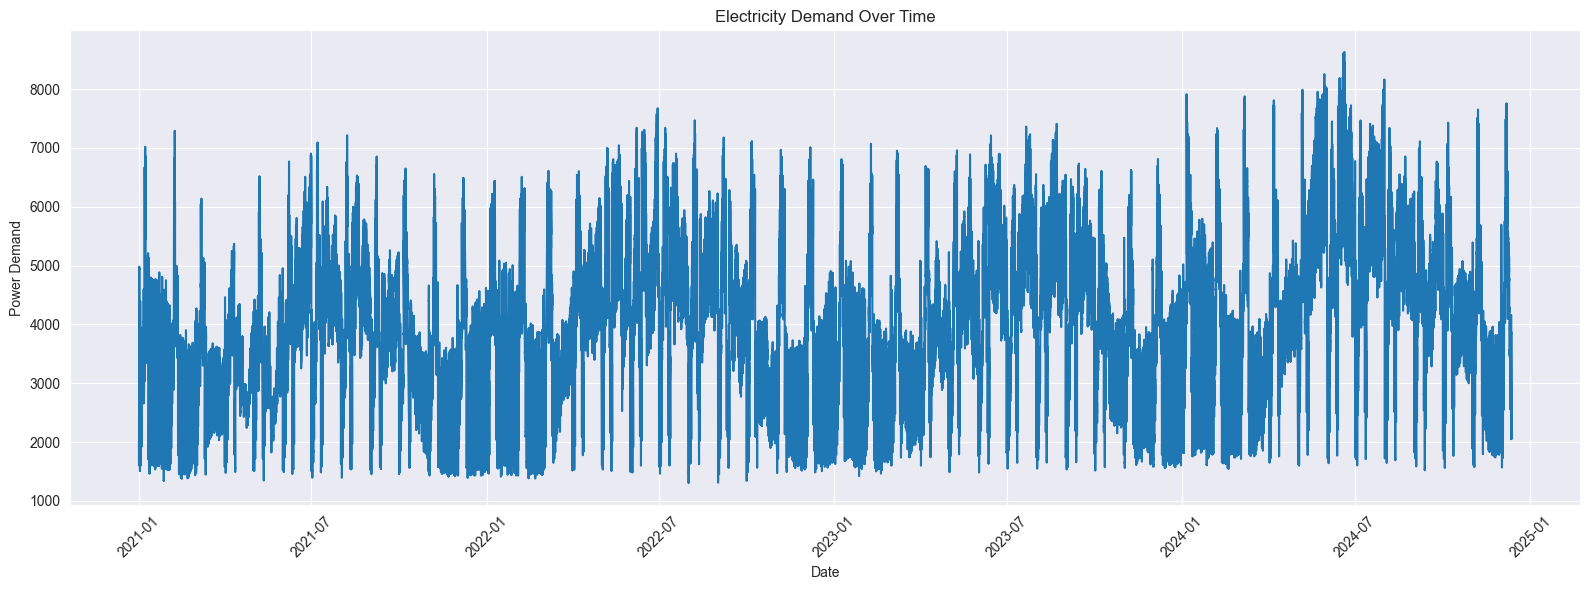

In [15]:
plt.figure(figsize=(16, 6))

plt.plot(
    df['datetime'],
    df['Power demand']
)

plt.title('Electricity Demand Over Time')
plt.xlabel('Date')
plt.ylabel('Power Demand')

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

##  Hourly Electricity Demand Analysis
The average electricity demand for each hour of the day is calculated
to identify daily consumption patterns.

In [16]:
hourly_demand = (
    df.groupby('hour')['Power demand']
    .mean()
)

hourly_demand

hour
0     3792.112634
1     3557.333805
2     3377.774280
3     3240.524671
4     3176.356721
5     3230.748024
6     3457.460624
7     3685.218492
8     3823.836286
9     4091.661066
10    4373.615395
11    4454.433513
12    4442.329377
13    4268.108175
14    4391.037059
15    4425.645414
16    4352.379575
17    4310.940507
18    4262.871519
19    4206.966368
20    4109.814902
21    4056.840323
22    4094.574624
23    3985.210713
Name: Power demand, dtype: float64

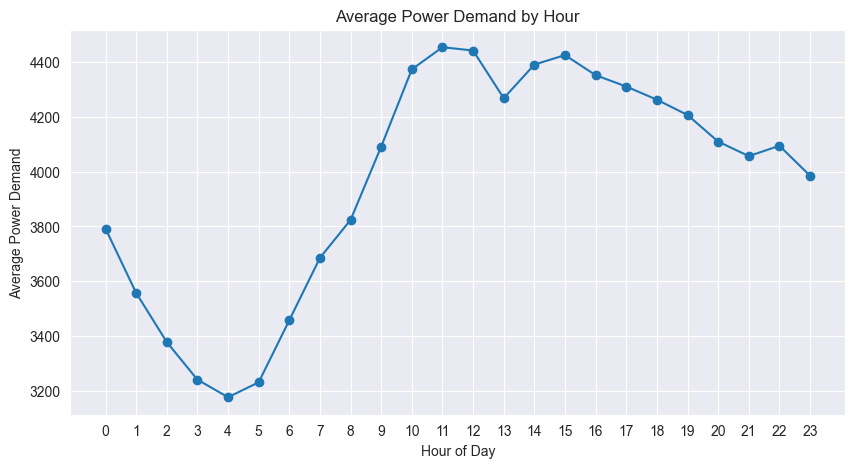

In [17]:
### 13.1 Average Power Demand by Hour
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand.values,
    marker='o'
)

plt.title('Average Power Demand by Hour')
plt.xlabel('Hour of Day')
plt.ylabel('Average Power Demand')
plt.xticks(range(24))

plt.grid(True)
plt.show()

## Monthly Electricity Demand Analysis

The average electricity demand for each month is calculated to identify
seasonal variations in energy consumption.

In [18]:
monthly_demand = (
    df.groupby('month')['Power demand']
    .mean()
)

monthly_demand

month
1     3524.805795
2     3219.576981
3     3364.072538
4     3919.203224
5     4413.270122
6     4858.022915
7     4777.389599
8     4661.248564
9     4336.157620
10    3621.955601
11    3255.330074
12    3468.926450
Name: Power demand, dtype: float64

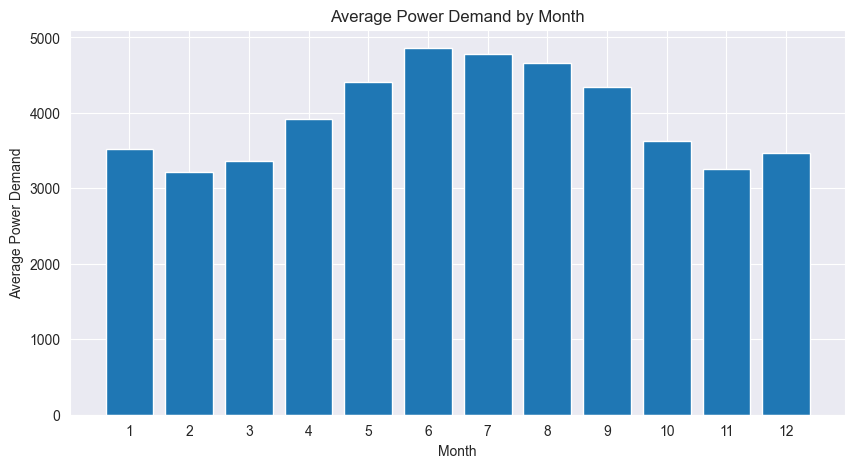

In [19]:
### 14.1 Average Power Demand by Month
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_demand.index,
    monthly_demand.values
)

plt.title('Average Power Demand by Month')
plt.xlabel('Month')
plt.ylabel('Average Power Demand')

plt.xticks(range(1, 13))

plt.show()

## 15. Temperature and Power Demand Relationship

The relationship between temperature and electricity demand is examined
to determine whether temperature may be useful as a predictive feature.

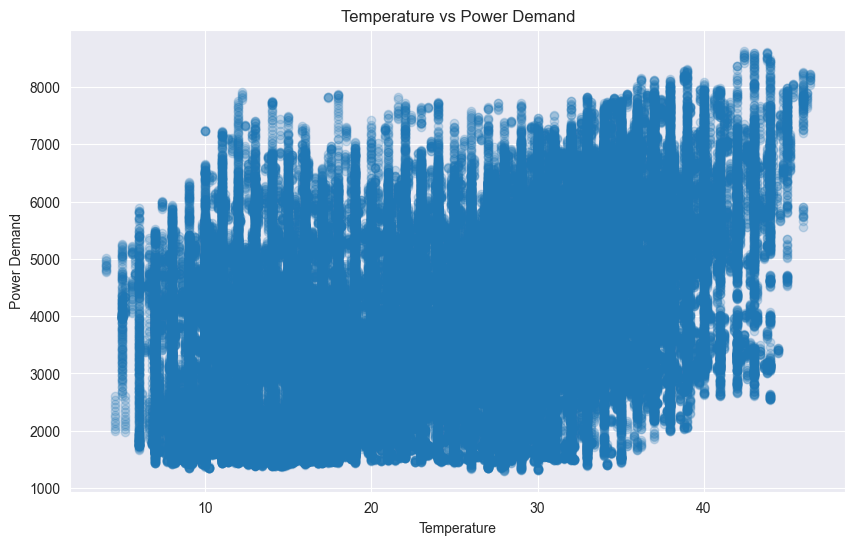

In [20]:
plt.figure(figsize=(10, 6))

plt.scatter(
    df['temp'],
    df['Power demand'],
    alpha=0.2
)

plt.title('Temperature vs Power Demand')
plt.xlabel('Temperature')
plt.ylabel('Power Demand')

plt.show()

## Correlation Analysis

Correlation analysis is performed to examine the relationships between
numerical variables and electricity demand. The results will also help
identify potentially useful features for the machine learning model.

In [21]:
correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

correlation_matrix['Power demand'].sort_values(
    ascending=False
)

Power demand    1.000000
moving_avg_3    0.999102
temp            0.469700
dwpt            0.285409
wspd            0.252669
year            0.248182
hour            0.223219
wdir            0.102651
month           0.044792
day             0.025972
minute          0.002123
rhum           -0.176559
pres           -0.404449
Name: Power demand, dtype: float64

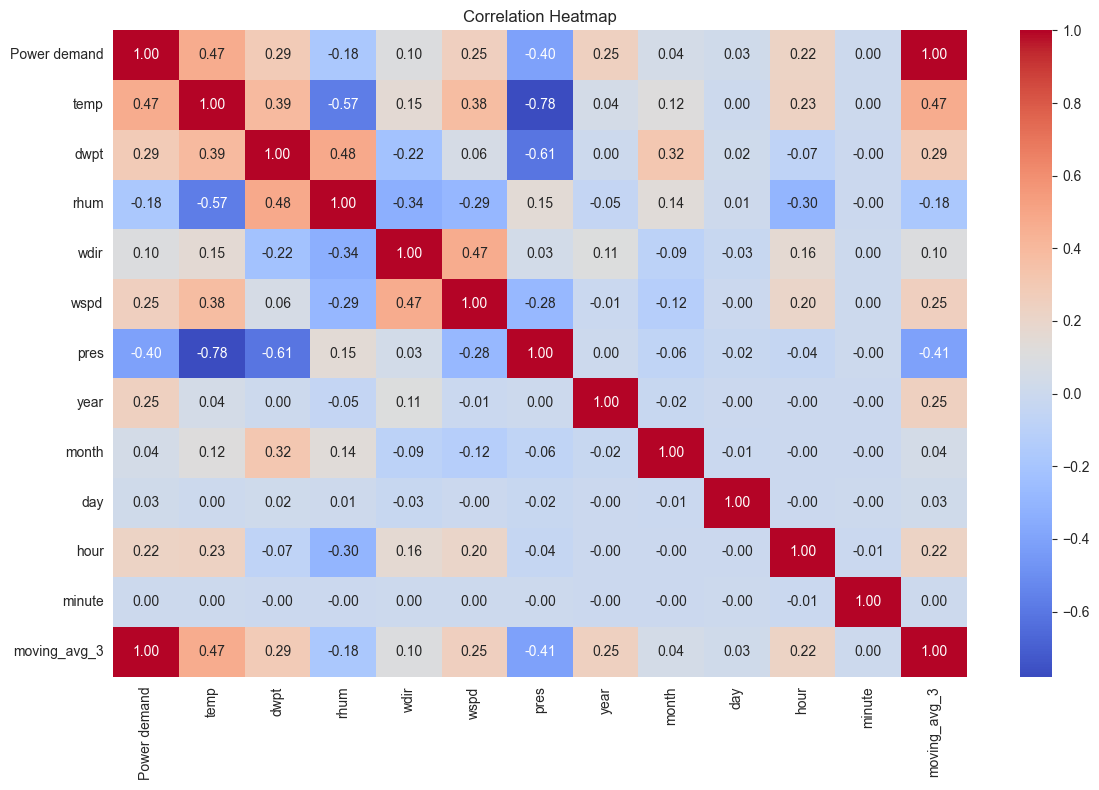

In [22]:
### 16.1 Correlation Heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

plt.title('Correlation Heatmap')

plt.tight_layout()
plt.show()

## Time-Based Feature Engineering
The `datetime` column contains useful temporal information that can
influence electricity demand. Additional features such as day of the
week, weekend indicator and time period are extracted from the datetime
variable.

In [23]:
# Create calendar and time-of-day features
df['day_of_week'] = df['datetime'].dt.dayofweek
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

def get_time_period(hour):
    if hour < 6:
        return 'Night'
    elif hour < 12:
        return 'Morning'
    elif hour < 18:
        return 'Afternoon'
    return 'Evening'

df['time_period'] = df['datetime'].dt.hour.map(get_time_period)


## Exact Five-Minute Forecasting Features

The original dataset contains some intervals longer than five minutes. Observations are aligned to a complete five-minute timeline so that each target is exactly five minutes ahead. Lag features use the exact historical timestamp. Rolling features use only past demand; the 24-hour rolling mean allows up to 20% missing readings in its window to avoid discarding excessive data after occasional gaps.


In [24]:
# Align observations to a regular five-minute timeline
df = df.set_index('datetime').asfreq('5min')
df.index.name = 'datetime'

# Recreate calendar features for the regular timeline
df['year'] = df.index.year
df['month'] = df.index.month
df['day'] = df.index.day
df['hour'] = df.index.hour
df['minute'] = df.index.minute
df['day_of_week'] = df.index.dayofweek
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)
df['time_period'] = df.index.hour.map(get_time_period)

# Recalculate the supplied moving average using current and previous
# observations only (no future information).
df['moving_avg_3'] = df['Power demand'].rolling(window=3, min_periods=3).mean()

# Exact historical lags on the five-minute timeline
for lag in [1, 2, 3, 12, 288]:
    df[f'lag_{lag}'] = df['Power demand'].shift(lag)

# Rolling features use only observations strictly before the prediction time.
# The 24-hour window requires at least 80% valid readings to tolerate occasional gaps.
for window in [3, 12, 288]:
    df[f'rolling_mean_{window}'] = (
        df['Power demand'].shift(1).rolling(
            window=window,
            min_periods=(window if window < 288 else int(0.80 * window))
        ).mean()
    )

# Because the index is now a complete five-minute timeline,
# shift(-1) represents exactly the next five-minute interval.
df['target'] = df['Power demand'].shift(-1)

historical_features = [
    'Power demand', 'moving_avg_3',
    'lag_1', 'lag_2', 'lag_3', 'lag_12', 'lag_288',
    'rolling_mean_3', 'rolling_mean_12', 'rolling_mean_288'
]

# Remove rows lacking required history or an exact five-minute target.
rows_before = len(df)
df = df.dropna(subset=historical_features + ['target']).copy()
rows_after = len(df)

df = df.reset_index()

print("Rows before feature validation:", rows_before)
print("Rows retained for modelling:", rows_after)
print("Rows removed due to missing history/target:", rows_before - rows_after)
print("Target horizon: exactly 5 minutes")

display(df[['datetime', 'Power demand', 'lag_1', 'lag_12',
            'lag_288', 'target']].head())


Rows before feature validation: 415009
Rows retained for modelling: 352609
Rows removed due to missing history/target: 62400
Target horizon: exactly 5 minutes


,datetime,Power demand,lag_1,lag_12,lag_288,target
0,2021-01-02 00:30:00,1819.80,1836.25,2324.68,2014.00,1793.80
1,2021-01-02 00:35:00,1793.80,1819.80,2294.15,2005.63,1777.79
2,2021-01-02 00:40:00,1777.79,1793.80,2237.88,1977.60,1753.54
3,2021-01-02 00:45:00,1753.54,1777.79,2226.09,1976.44,1728.98
4,2021-01-02 00:50:00,1728.98,1753.54,2163.08,1954.37,1726.88


## Feature Validation

Rows without the required historical demand observations or an exact five-minute-ahead target are excluded. Remaining missing weather values are handled later using an imputer fitted on the training data only.


## Dataset After Feature Engineering

The dataset shape and structure are checked after creating the
forecasting features and removing rows that cannot be used for training.

## Define Features and Target

The target is electricity demand at the timestamp exactly five minutes after the current observation. All input features are available at the prediction timestamp or earlier.


In [25]:
# Define target and model input features
target_column = 'target'
X = df.drop(columns=[target_column, 'datetime'])
y = df[target_column]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)


Feature matrix shape: (352609, 24)
Target shape: (352609,)


## Chronological Train-Test Split
Since this project predicts future electricity demand, the data is
divided chronologically rather than randomly. Earlier observations are
used for training and later observations are used for testing.

This approach prevents future observations from being used to train the
model and better represents a real-world forecasting scenario.

In [26]:
# Chronological 80:20 train-test split
split_index = int(len(X) * 0.80)

# A one-row gap prevents the final training label from reaching into
# the first test timestamp (the target is one 5-minute step ahead).
X_train = X.iloc[:split_index - 1].copy()
X_test = X.iloc[split_index:].copy()
y_train = y.iloc[:split_index - 1].copy()
y_test = y.iloc[split_index:].copy()

print('Training samples:', len(X_train))
print('Testing samples:', len(X_test))
print('Training period:', df['datetime'].iloc[0], 'to', df['datetime'].iloc[split_index - 2])
print('Testing period:', df['datetime'].iloc[split_index], 'to', df['datetime'].iloc[-1])
print('One-row temporal gap applied to prevent target overlap.')


Training samples: 282086
Testing samples: 70522
Training period: 2021-01-02 00:30:00 to 2024-03-08 04:25:00
Testing period: 2024-03-08 04:35:00 to 2024-12-11 22:25:00
One-row temporal gap applied to prevent target overlap.


## Data Leakage Prevention
The train-test split is performed before fitting preprocessing techniques
such as imputation, encoding and scaling. This ensures that information
from the test dataset is not used when learning preprocessing parameters
from the training data.

##  Missing Value Handling
Missing values are handled after the train-test split to prevent data
leakage. The missing-value pattern in the training and testing datasets
is examined before selecting an imputation strategy.

In [27]:
# Inspect missing values and identify feature types
print("Missing values in training data:", X_train.isnull().sum().sum())
print("Missing values in testing data:", X_test.isnull().sum().sum())

numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(include='object').columns.tolist()
print("\\nNumerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Fit imputer on training data only
imputer = SimpleImputer(strategy='median')
X_train_numeric = pd.DataFrame(
    imputer.fit_transform(X_train[numeric_features]),
    columns=numeric_features, index=X_train.index
)
X_test_numeric = pd.DataFrame(
    imputer.transform(X_test[numeric_features]),
    columns=numeric_features, index=X_test.index
)


Missing values in training data: 456
Missing values in testing data: 0
\nNumerical features: ['Power demand', 'temp', 'dwpt', 'rhum', 'wdir', 'wspd', 'pres', 'year', 'month', 'day', 'hour', 'minute', 'moving_avg_3', 'day_of_week', 'is_weekend', 'lag_1', 'lag_2', 'lag_3', 'lag_12', 'lag_288', 'rolling_mean_3', 'rolling_mean_12', 'rolling_mean_288']
Categorical features: ['time_period']


In [28]:
# One-hot encode nominal categorical features
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

X_train_categorical = pd.DataFrame(
    encoder.fit_transform(X_train[categorical_features]),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_train.index
)
X_test_categorical = pd.DataFrame(
    encoder.transform(X_test[categorical_features]),
    columns=encoder.get_feature_names_out(categorical_features),
    index=X_test.index
)

# Combine numerical and encoded categorical features
X_train_processed = pd.concat([X_train_numeric, X_train_categorical], axis=1)
X_test_processed = pd.concat([X_test_numeric, X_test_categorical], axis=1)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Remaining missing values:",
      X_train_processed.isnull().sum().sum(),
      X_test_processed.isnull().sum().sum())


Processed training shape: (282086, 27)
Processed testing shape: (70522, 27)
Remaining missing values: 0 0


## Numerical Feature Skewness Analysis

The skewness of the numerical features is examined before applying any
transformation. This helps determine whether any feature has a strongly
asymmetric distribution that may require transformation.

A transformation will only be applied where it is justified by the
observed distribution.

In [29]:
# Examine skewness in numerical training features
skewness = X_train_numeric.skew().sort_values(ascending=False)
high_skew = skewness[abs(skewness) > 1]

display(skewness.to_frame('Skewness'))
print("Features with absolute skewness greater than 1:", high_skew.index.tolist())


,Skewness
is_weekend,0.926073
wspd,0.631376
rolling_mean_288,0.581923
lag_288,0.250557
Power demand,0.233618
lag_1,0.231201
moving_avg_3,0.230989
lag_2,0.228883
rolling_mean_3,0.228669
lag_3,0.226671


Features with absolute skewness greater than 1: []


In [30]:
### 33.2 Distribution of Potentially Skewed Features
for column in high_skew.index:
    plt.figure(figsize=(8, 4))
    plt.hist(X_train_numeric[column].dropna(), bins=40)
    plt.title(f'Distribution of {column}')
    plt.xlabel(column)
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()


## Transformation Decision

Skewness is examined before applying transformations. No automatic log transformation is applied; original values are retained unless the observed distributions justify a change.


## Feature Scaling Using Standardization
The numerical features have different units and ranges. Standardization
is therefore applied so that the numerical features have approximately
zero mean and unit variance.

The scaler is fitted only on the training data and then used to transform
both the training and testing data, preventing data leakage.

In [31]:
# Standardize numerical features using training data only
scaler = StandardScaler()

X_train_scaled_numeric = pd.DataFrame(
    scaler.fit_transform(X_train_numeric),
    columns=X_train_numeric.columns, index=X_train_numeric.index
)
X_test_scaled_numeric = pd.DataFrame(
    scaler.transform(X_test_numeric),
    columns=X_test_numeric.columns, index=X_test_numeric.index
)

# Combine scaled numerical and encoded categorical features
X_train_processed = pd.concat([X_train_scaled_numeric, X_train_categorical], axis=1)
X_test_processed = pd.concat([X_test_scaled_numeric, X_test_categorical], axis=1)

print("Final training shape:", X_train_processed.shape)
print("Final testing shape:", X_test_processed.shape)
print("Missing values (train/test):",
      X_train_processed.isnull().sum().sum(),
      X_test_processed.isnull().sum().sum())


Final training shape: (282086, 27)
Final testing shape: (70522, 27)
Missing values (train/test): 0 0


## Outlier Detection

Outliers are investigated in the numerical features using the
Interquartile Range (IQR) method. Extreme observations are not removed
automatically because unusually high or low electricity demand may
represent genuine consumption patterns rather than measurement errors.

In [32]:
# Detect outliers in numerical training features using the IQR method
outlier_summary = []

for column in numeric_features:
    q1 = X_train_numeric[column].quantile(0.25)
    q3 = X_train_numeric[column].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = (X_train_numeric[column] < lower_bound) | (X_train_numeric[column] > upper_bound)

    outlier_summary.append({
        'Feature': column,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': outliers.sum(),
        'Outlier Percentage': outliers.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_summary).sort_values(
    'Outlier Percentage', ascending=False
)
display(outlier_summary)


,Feature,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
5,wspd,-3.300000,19.900000,6412,2.273066
19,lag_288,515.590000,7109.590000,513,0.181859
0,Power demand,538.410000,7123.830000,487,0.172642
15,lag_1,536.850000,7123.950000,480,0.170161
12,moving_avg_3,537.873333,7123.206667,476,0.168743
16,lag_2,535.642500,7123.902500,472,0.167325
20,rolling_mean_3,536.700000,7123.200000,468,0.165907
17,lag_3,534.213750,7124.203750,464,0.164489
21,rolling_mean_12,530.744688,7126.037188,399,0.141446
18,lag_12,514.041250,7134.691250,389,0.137901


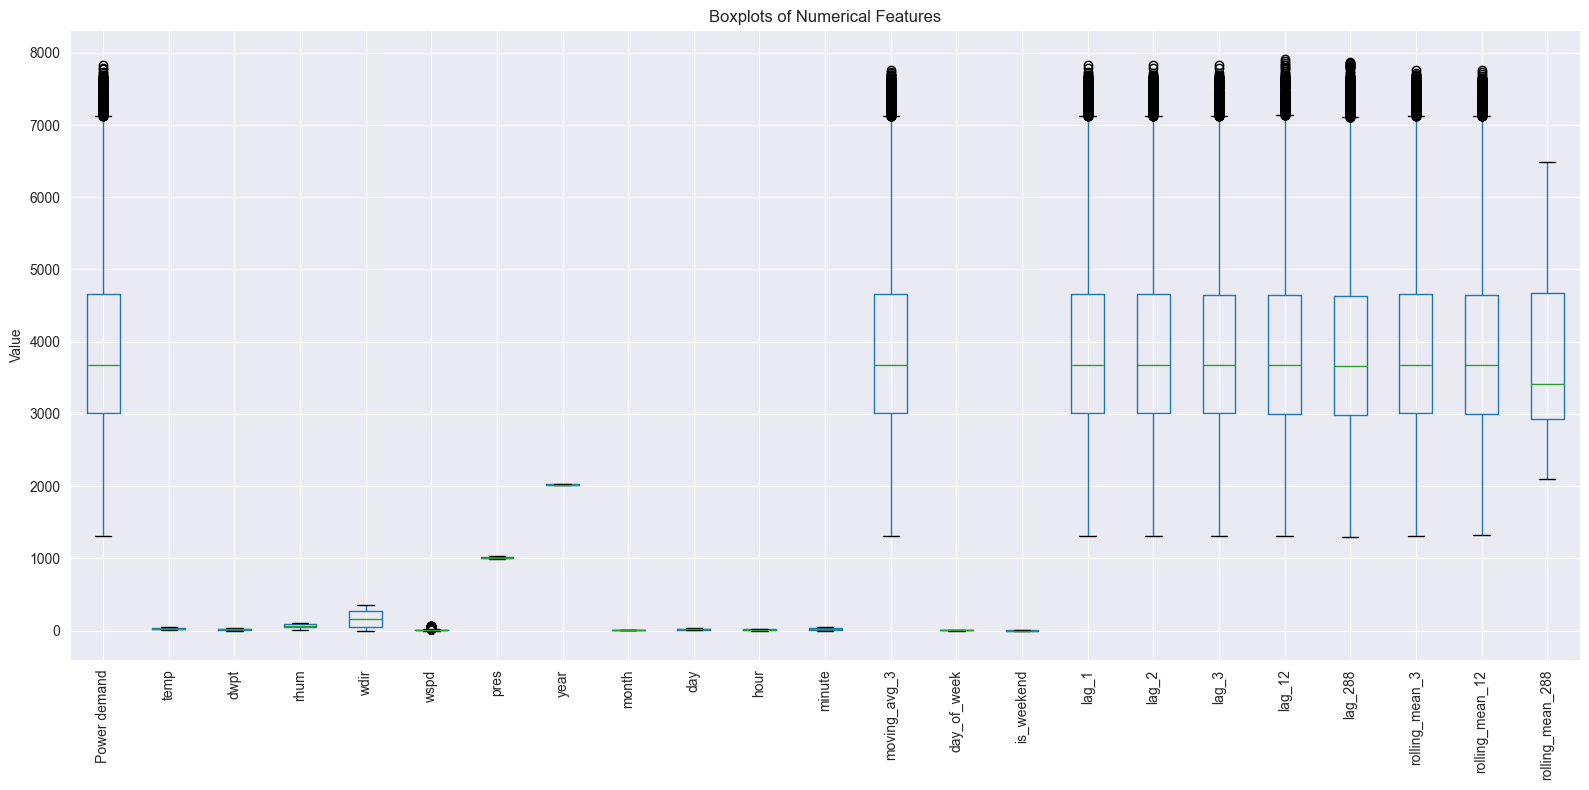

In [33]:
### 37.1 Boxplots of Numerical Features
plt.figure(figsize=(16, 8))

X_train_numeric.boxplot()

plt.title('Boxplots of Numerical Features')
plt.ylabel('Value')

plt.xticks(rotation=90)
plt.tight_layout()

plt.show()

## Feature Selection

Feature selection is applied to identify the most relevant input
features for predicting the next 5-minute electricity demand.

Feature selection can reduce unnecessary or less informative variables,
simplify the model and improve interpretability.

SelectKBest with the ANOVA F-test for regression (`f_regression`) is used
to rank the numerical input features according to their relationship
with the target variable.

In [34]:
# Select the 10 most relevant features using the ANOVA F-test
selector = SelectKBest(score_func=f_regression, k=10)
X_train_selected = selector.fit_transform(X_train_processed, y_train)
X_test_selected = selector.transform(X_test_processed)

selected_features = X_train_processed.columns[selector.get_support()]
feature_scores = pd.DataFrame({
    'Feature': X_train_processed.columns,
    'F-Score': selector.scores_
}).sort_values('F-Score', ascending=False)

print("Features before selection:", X_train_processed.shape[1])
print("Features after selection:", len(selected_features))
print("Selected features:", selected_features.tolist())
display(feature_scores)


Features before selection: 27
Features after selection: 10
Selected features: ['Power demand', 'moving_avg_3', 'lag_1', 'lag_2', 'lag_3', 'lag_12', 'lag_288', 'rolling_mean_3', 'rolling_mean_12', 'rolling_mean_288']


,Feature,F-Score
0,Power demand,2.467817e+08
12,moving_avg_3,1.213442e+08
15,lag_1,1.033016e+08
20,rolling_mean_3,6.186171e+07
16,lag_2,5.667403e+07
17,lag_3,3.590970e+07
21,rolling_mean_12,1.375711e+07
18,lag_12,4.740737e+06
19,lag_288,5.404428e+05
22,rolling_mean_288,4.964825e+05


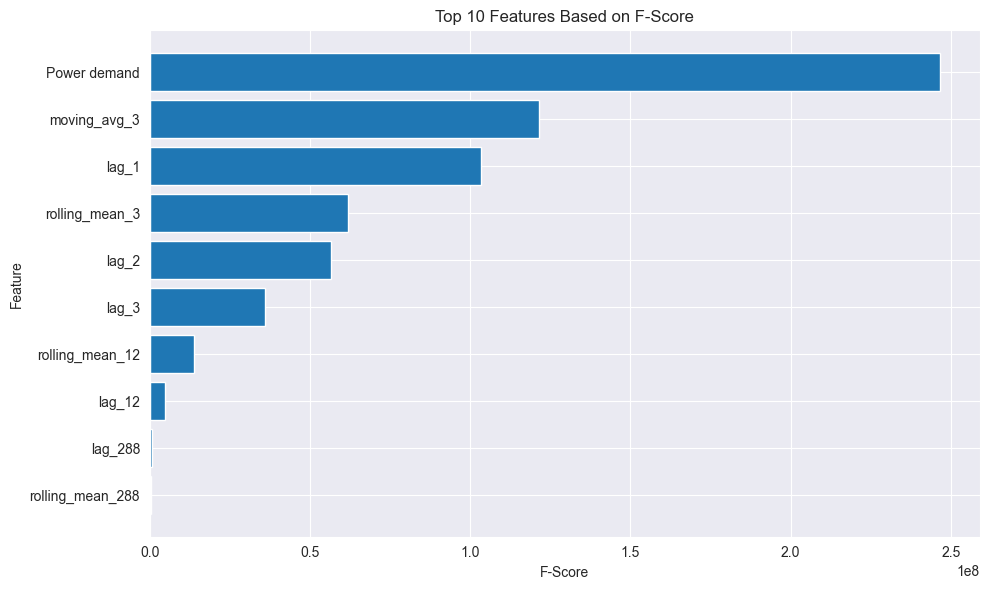

In [35]:
### 39.4 Top Feature Selection Scores
top_features = feature_scores.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features['Feature'][::-1],
    top_features['F-Score'][::-1]
)

plt.title('Top 10 Features Based on F-Score')
plt.xlabel('F-Score')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## Feature Selection Decision and Justification

SelectKBest with the regression F-test retains the ten highest-scoring features. This selection is fitted using training data only. It preserves original feature names and supports model interpretability.


##  Model Training

The selected and preprocessed features are used to train machine
learning regression models. The target variable is the electricity
demand for the next 5-minute interval.

## Linear Regression Model

Linear Regression is used as the baseline regression model. It provides
a simple reference point for predicting the next 5-minute electricity
demand from the selected features.

In [36]:
# Train and evaluate Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_selected, y_train)
y_pred_linear = linear_model.predict(X_test_selected)

mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

print("Linear Regression Results")
print(f"MAE:  {mae_linear:.4f}")
print(f"RMSE: {rmse_linear:.4f}")
print(f"R²:   {r2_linear:.6f}")


Linear Regression Results
MAE:  23.6682
RMSE: 37.0274
R²:   0.999236


##  Random Forest Regression Model

Random Forest Regressor is used as a second regression model. Unlike
Linear Regression, Random Forest can capture nonlinear relationships
between historical electricity demand, weather conditions and temporal
features.

In [37]:
# Train and evaluate Random Forest with controlled complexity for the large time-series dataset
rf_model = RandomForestRegressor(
    n_estimators=50,
    max_depth=12,
    min_samples_leaf=3,
    max_samples=0.5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_selected, y_train)
y_pred_rf = rf_model.predict(X_test_selected)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Results")
print(f"MAE:  {mae_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"R²:   {r2_rf:.6f}")


Random Forest Results
MAE:  26.2540
RMSE: 49.6810
R²:   0.998625


## Model Performance Comparison

The performance of the Linear Regression and Random Forest models is
compared using MAE, RMSE and R² on the unseen testing data.

In [38]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Random Forest'
    ],
    'MAE': [
        mae_linear,
        mae_rf
    ],
    'RMSE': [
        rmse_linear,
        rmse_rf
    ],
    'R²': [
        r2_linear,
        r2_rf
    ]
})

results

,Model,MAE,RMSE,R²
0,Linear Regression,23.668220,37.027398,0.999236
1,Random Forest,26.253957,49.680959,0.998625


##  Actual vs Predicted Power Demand — Linear Regression
The actual electricity demand values are compared with the values
predicted by the Linear Regression model.

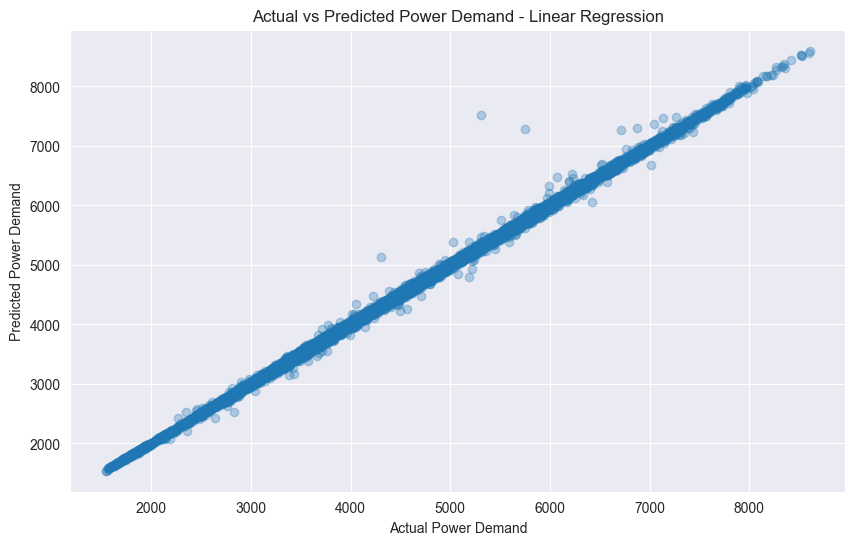

In [39]:
plt.figure(figsize=(10, 6))

plot_idx = np.linspace(0, len(y_test) - 1, min(10000, len(y_test)), dtype=int)
plt.scatter(y_test.iloc[plot_idx], y_pred_linear[plot_idx], alpha=0.3)

plt.xlabel('Actual Power Demand')
plt.ylabel('Predicted Power Demand')
plt.title('Actual vs Predicted Power Demand - Linear Regression')

plt.show()

## Actual vs Predicted Power Demand — Random Forest

The actual electricity demand values are compared with the values
predicted by the Random Forest model.

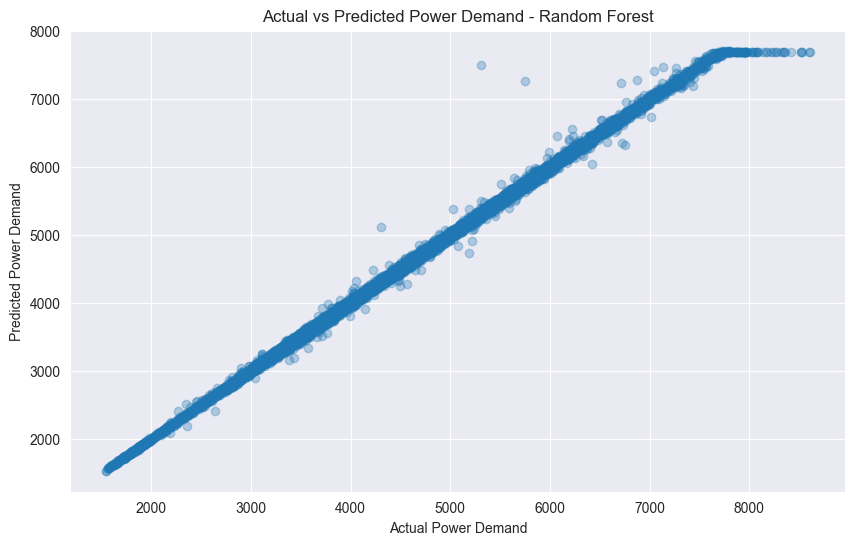

In [40]:
plt.figure(figsize=(10, 6))

plot_idx = np.linspace(0, len(y_test) - 1, min(10000, len(y_test)), dtype=int)
plt.scatter(y_test.iloc[plot_idx], y_pred_rf[plot_idx], alpha=0.3)

plt.xlabel('Actual Power Demand')
plt.ylabel('Predicted Power Demand')
plt.title('Actual vs Predicted Power Demand - Random Forest')

plt.show()

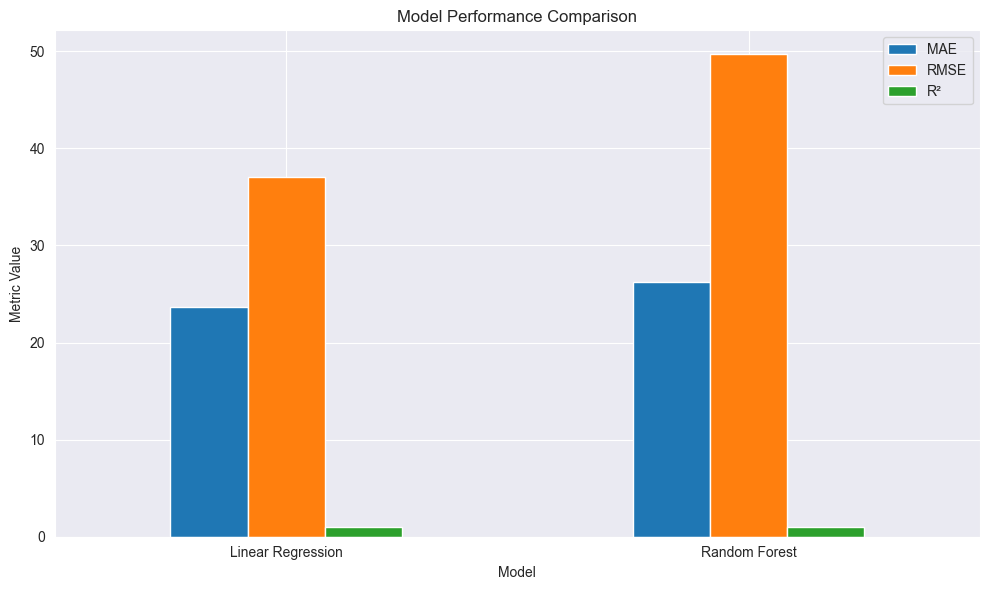

In [41]:
results.set_index('Model')[['MAE', 'RMSE', 'R²']].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Model Performance Comparison')
plt.xlabel('Model')
plt.ylabel('Metric Value')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Results and Observations

The models were evaluated on a chronologically held-out test period using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and R². Linear Regression achieved an MAE of **23.6682**, RMSE of **37.0274** and R² of **0.999236**. Random Forest achieved an MAE of **26.2538**, RMSE of **49.6807** and R² of **0.998625**.

Linear Regression performed better on all three reported test metrics: it produced lower MAE and RMSE and a higher R² score. Therefore, Linear Regression is selected as the best model for this notebook’s exact five-minute-ahead forecasting setup. These results were regenerated after correcting timestamp alignment, lag features, rolling features and the chronological split boundary.
